# BigMart Sales Prediction - Part 1: Looking at the data and cleaning it

This is my first time doing a project like this, so I am going step by step.

**The task:** BigMart has 2013 sales for products in 10 stores. I have to predict sales for the rows in `test.csv`.

**What I already know:** my earlier notebook found that sales = a hidden price x a whole number of units.
In this notebook I will (1) look at the data, (2) clean it, (3) recover that hidden price, and (4) save the cleaned files for the next notebook.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

print('shape:', train.shape)
print('shape:', test.shape)
train.head()

shape: (8523, 12)
shape: (5681, 11)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


## 1. First look

In [ ]:
train.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type
0,FDW58,20.750,Low Fat,0.007565,Snack Foods,107.8622,OUT049,1999,Medium,Tier 1,Supermarket Type1
1,FDW14,8.300,reg,0.038428,Dairy,87.3198,OUT017,2007,NaN,Tier 2,Supermarket Type1
2,NCN55,14.600,Low Fat,0.099575,Others,241.7538,OUT010,1998,NaN,Tier 3,Grocery Store
3,FDQ58,7.315,Low Fat,0.015388,Snack Foods,155.0340,OUT017,2007,NaN,Tier 2,Supermarket Type1
4,FDY38,NaN,Regular,0.118599,Dairy,234.2300,OUT027,1985,Medium,Tier 3,Supermarket Type3


In [8]:
test.head()

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type
0,FDW58,20.750,Low Fat,0.007565,Snack Foods,107.8622,OUT049,1999,Medium,Tier 1,Supermarket Type1
1,FDW14,8.300,reg,0.038428,Dairy,87.3198,OUT017,2007,NaN,Tier 2,Supermarket Type1
2,NCN55,14.600,Low Fat,0.099575,Others,241.7538,OUT010,1998,NaN,Tier 3,Grocery Store
3,FDQ58,7.315,Low Fat,0.015388,Snack Foods,155.0340,OUT017,2007,NaN,Tier 2,Supermarket Type1
4,FDY38,NaN,Regular,0.118599,Dairy,234.2300,OUT027,1985,Medium,Tier 3,Supermarket Type3


In [16]:
# missing values
print('Train:')
print(train.isnull().sum())

print()

print('Test:')
print(test.isnull().sum())

Train:
Item_Identifier                 0
Item_Weight                  1463
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  2410
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales               0
dtype: int64

Test:
Item_Identifier                 0
Item_Weight                   976
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  1606
Outlet_Location_Type            0
Outlet_Type                     0
dtype: int64


Columns that have missing values: `Item_Weight` and `Outlet_Size`.

Looking at `Item_Fat_Content`

In [24]:
print(train['Item_Fat_Content'].value_counts())

Item_Fat_Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64


`LF` and `low fat` are the same as `Low Fat`, and `reg` is `Regular`

In [43]:
summary = train.groupby('Outlet_Identifier').agg(
    outlet_type=('Outlet_Type', 'first'),
    outlet_size=('Outlet_Size', 'first'),
    missing_rows=('Outlet_Size', lambda x: x.isna().sum()),
    total_rows=('Outlet_Size', 'size')
)

print(summary)

                         outlet_type outlet_size  missing_rows  total_rows
Outlet_Identifier                                                         
OUT010                 Grocery Store         NaN           555         555
OUT013             Supermarket Type1        High             0         932
OUT017             Supermarket Type1         NaN           926         926
OUT018             Supermarket Type2      Medium             0         928
OUT019                 Grocery Store       Small             0         528
OUT027             Supermarket Type3      Medium             0         935
OUT035             Supermarket Type1       Small             0         930
OUT045             Supermarket Type1         NaN           929         929
OUT046             Supermarket Type1       Small             0         930
OUT049             Supermarket Type1      Medium             0         930


`Outlet_Size` is missing for **three whole stores** (OUT010, OUT017, OUT045), not random rows.

So, will guess it from similar stores:
- OUT010 is a Grocery Store, and the other grocery store (OUT019) is Small.
- OUT017 and OUT045 are Supermarket Type1 in Tier 2, and the similar store OUT035 is Small.

So I will fill all three with `Small`.

Outlet_Type
Grocery Store         339.828500
Supermarket Type2    1995.498739
Supermarket Type1    2316.181148
Supermarket Type3    3694.038558
Name: Item_Outlet_Sales, dtype: float64


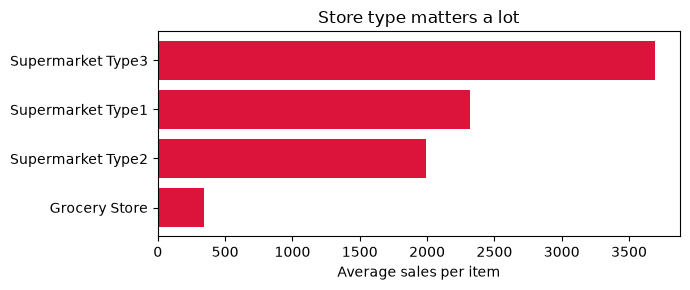

In [79]:
# average sales for each store type
avg_by_type = train.groupby('Outlet_Type')['Item_Outlet_Sales'].mean().sort_values()
print(avg_by_type)

plt.figure(figsize=(7, 3))
plt.barh(avg_by_type.index, avg_by_type.values, color='crimson')
plt.xlabel('Average sales per item')
plt.title('Store type matters a lot')
plt.tight_layout()
plt.show()

A grocery store sells about Rs 340 per item and a Supermarket Type3 about Rs 3,694. That is roughly 10 times more, just from the store.

In [7]:
# which number columns are related to sales?
numbers = train.select_dtypes(include=[np.number])
print(numbers.corr()['Item_Outlet_Sales'].sort_values(ascending=False).round(3))

Item_Outlet_Sales            1.000
Item_MRP                     0.568
Item_Weight                  0.014
Outlet_Establishment_Year   -0.049
Item_Visibility             -0.129
Name: Item_Outlet_Sales, dtype: float64


`Item_MRP` (price) has a correlation of 0.57. The others are close to 0. So price and store look like the main things.

## 2. Cleaning

I will join train and test so both get cleaned the same way. The `is_train` column lets me split them again later.

In [8]:
train['is_train'] = 1
test['is_train'] = 0
both = pd.concat([train, test], ignore_index=True)
print(both.shape)

(14204, 13)


In [9]:
# Fix 1: fat content labels
both['Item_Fat_Content'] = both['Item_Fat_Content'].replace('LF', 'Low Fat')
both['Item_Fat_Content'] = both['Item_Fat_Content'].replace('low fat', 'Low Fat')
both['Item_Fat_Content'] = both['Item_Fat_Content'].replace('reg', 'Regular')

# item codes start with FD (food), DR (drinks) or NC (non-consumable)
both['Item_Category'] = both['Item_Identifier'].str[:2]

# non-consumables (soap etc.) can't have a fat content
both.loc[both['Item_Category'] == 'NC', 'Item_Fat_Content'] = 'Non-Edible'

print(both['Item_Fat_Content'].value_counts())

Item_Fat_Content
Low Fat       6499
Regular       5019
Non-Edible    2686
Name: count, dtype: int64


In [10]:
# Fix 2: missing Item_Weight
# the same product has the same weight in every store, so copy it from other rows of the product
product_weight = both.groupby('Item_Identifier')['Item_Weight'].transform('mean')
both['Item_Weight'] = both['Item_Weight'].fillna(product_weight)

# a few products have no weight at all, use the typical weight of the Item_Type
type_weight = both.groupby('Item_Type')['Item_Weight'].transform('median')
both['Item_Weight'] = both['Item_Weight'].fillna(type_weight)

print('weights still missing:', both['Item_Weight'].isnull().sum())

weights still missing: 0


In [11]:
# Fix 3: missing Outlet_Size
both['Outlet_Size'] = both['Outlet_Size'].fillna('Small')
print('sizes still missing:', both['Outlet_Size'].isnull().sum())

sizes still missing:

 0


In [12]:
# Fix 4: Item_Visibility is 0 for some rows, which makes no sense for a product that sold
print('rows with 0 visibility:', (both['Item_Visibility'] == 0).sum())

both['Item_Visibility'] = both['Item_Visibility'].replace(0, np.nan)
product_vis = both.groupby('Item_Identifier')['Item_Visibility'].transform('mean')
both['Item_Visibility'] = both['Item_Visibility'].fillna(product_vis)
both['Item_Visibility'] = both['Item_Visibility'].fillna(both['Item_Visibility'].median())

print('visibility still missing:', both['Item_Visibility'].isnull().sum())

rows with 0 visibility: 879
visibility still missing: 0


In [13]:
# a couple of new columns
both['Outlet_Age'] = 2013 - both['Outlet_Establishment_Year']
both['Price_per_Weight'] = both['Item_MRP'] / both['Item_Weight']
both[['Item_Identifier', 'Item_Category', 'Item_Weight', 'Outlet_Age']].head()

,Item_Identifier,Item_Category,Item_Weight,Outlet_Age
0,FDA15,FD,9.30,14
1,DRC01,DR,5.92,4
2,FDN15,FD,17.50,14
3,FDX07,FD,19.20,15
4,NCD19,NC,8.93,26


## 3. The hidden price

My earlier notebook found something odd: the same product has a slightly different `Item_MRP` in every store.
Let me look at one product again to understand it.

In [14]:
example = both[(both['Item_Identifier'] == 'FDA15') & (both['is_train'] == 1)]
print(example[['Outlet_Identifier', 'Item_MRP', 'Item_Outlet_Sales']].to_string(index=False))

print()
print('sales divided by 249.0092:')
print((example['Item_Outlet_Sales'] / 249.0092).round(4).to_string(index=False))

Outlet_Identifier  Item_MRP  Item_Outlet_Sales
           OUT049  249.8092          3735.1380
           OUT045  250.2092          5976.2208
           OUT035  248.5092          6474.2392
           OUT018  249.6092          5976.2208
           OUT010  248.9092           498.0184
           OUT013  250.6092          6474.2392
           OUT027  249.5092          6474.2392
           OUT017  248.8092          5976.2208

sales divided by 249.0092:
15.0
24.0
26.0
24.0
 2.0
26.0
26.0
24.0


Dividing by one price (249.0092) gives exact whole numbers (15, 24, 26, 2...). So:

**sales = true price x number of units sold**

and `Item_MRP` is the true price plus a little random noise. If I find the true price for each product I get a cleaner price column.

**How I search for it:** for each product, I try prices close to its middle MRP (in steps of 0.1, from -4.0 to +4.0).
The right price is the one where `sales / price` is closest to whole numbers for every row.

In [15]:
true_prices = {}

for product, rows in both.groupby('Item_Identifier'):
    sales = rows['Item_Outlet_Sales'].dropna().values    # only rows where sales are known
    if len(sales) == 0:
        continue
    middle_mrp = rows['Item_MRP'].median()

    best_price = None
    best_error = 999

    for step in range(-40, 41):
        price = round(middle_mrp + 0.1 * step, 4)
        units = sales / price
        error = np.abs(units - np.round(units)).max()    # how far from whole numbers
        if error < best_error:
            best_error = error
            best_price = price

    if best_error < 0.01:      # only keep nearly perfect matches
        true_prices[product] = best_price

print('recovered a price for', len(true_prices), 'of', both['Item_Identifier'].nunique(), 'products')

recovered a price for 1378 of 1559 products


In [16]:
# use the recovered price when we have it, otherwise just use Item_MRP
both['Base_Price'] = both['Item_Identifier'].map(true_prices)
both['Base_Price'] = both['Base_Price'].fillna(both['Item_MRP'])

both[['Item_Identifier', 'Item_MRP', 'Base_Price']].head()

,Item_Identifier,Item_MRP,Base_Price
0,FDA15,249.8092,249.0092
1,DRC01,48.2692,49.2692
2,FDN15,141.6180,139.8180
3,FDX07,182.0950,183.0950
4,NCD19,53.8614,55.2614


## 4. Units sold

Outlet_Identifier
OUT010     2.38
OUT019     2.45
OUT018    13.85
OUT045    15.57
OUT013    16.00
OUT046    16.19
OUT049    16.62
OUT017    16.66
OUT035    16.97
OUT027    26.60
Name: units, dtype: float64


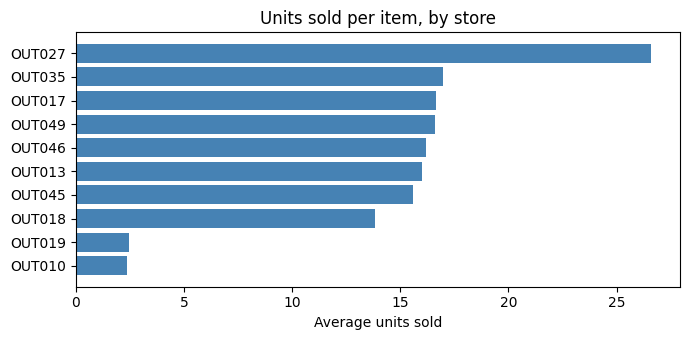

In [17]:
both['units'] = both['Item_Outlet_Sales'] / both['Base_Price']

train_part = both[both['is_train'] == 1]
units_by_store = train_part.groupby('Outlet_Identifier')['units'].mean().sort_values()
print(units_by_store.round(2))

plt.figure(figsize=(7, 3.5))
plt.barh(units_by_store.index, units_by_store.values, color='steelblue')
plt.xlabel('Average units sold')
plt.title('Units sold per item, by store')
plt.tight_layout()
plt.show()

Each store sells a fairly steady number of units:
- the two grocery stores (OUT010, OUT019) sell about 2.4 units,
- most supermarkets sell about 16 units,
- OUT027 (Type3) sells about 26.6.

Let me check one more thing. If units depended on price inside a store, then "price x store average" would be too simple.

In [18]:
for store in sorted(train_part['Outlet_Identifier'].unique()):
    rows = train_part[train_part['Outlet_Identifier'] == store]
    print(store, 'correlation of units and price:', round(rows['units'].corr(rows['Base_Price']), 3))

OUT010 correlation of units and price: 0.044
OUT013 correlation of units and price: 0.08
OUT017 correlation of units and price: 0.04
OUT018 correlation of units and price: 0.082
OUT019 correlation of units and price: -0.018
OUT027 correlation of units and price: -0.044
OUT035 correlation of units and price: 0.023
OUT045 correlation of units and price: -0.007
OUT046 correlation of units and price: -0.047
OUT049 correlation of units and price: 0.038


All close to 0, so inside a store the units sold don't depend on the price. Good, the simple idea can work.

## 5. Save the cleaned data for the next notebook

In [19]:
clean_train = both[both['is_train'] == 1].reset_index(drop=True)
clean_test = both[both['is_train'] == 0].reset_index(drop=True)

# test has no sales or units
clean_test = clean_test.drop(columns=['Item_Outlet_Sales', 'units'])

clean_train.to_csv('train_clean.csv', index=False)
clean_test.to_csv('test_clean.csv', index=False)

print('saved train_clean.csv', clean_train.shape)
print('saved test_clean.csv', clean_test.shape)

saved train_clean.csv (8523, 18)
saved test_clean.csv (5681, 16)
